<a href="https://colab.research.google.com/github/egomez-DA/An-lisis_actividad-s-smica_2006-2026/blob/main/An%C3%A1lisis_actividad_s%C3%ADsmica_2006_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Proyecto: Análisis de actividad sísmica en la República Mexicana, periodo 2006- 2026.

Objetivo: evaluar la actividad sísmica en México en los últimos veinte años, generando visualizaciones que permitan responder:
- **Actividad sísmica anual en los últimos 20 años**
- **Magnitud de los sismos**
- **¿En qué regiones tembló más?**
- **¿Por qué tiembla mucho en la Ciudad de México?**
- **¿Es septiembre el mes de los sismos?**

El **Servicio Sismológico Nacional (SSN)** tiene sede en el Instituto de Geofísica de la UNAM y su objetivo es proporcionar información oportuna sobre la ocurrencia de sismos en el territorio nacional y determinar sus principales parámetros como son la magnitud y el epicentro.

Más información en: http://www.ssn.unam.mx/

## ⚠️ DISCLAIMER

Este notebook tiene fines didácticos. EDA (exploratory data analysis) y análisis de datos. Los resultados no representan información oficial.

Elaborado por DA: Erika Gómez.

# 📂 Descripción de los datasets

🔹 **catálogo de sismos 2006-2026**  
Tabla con fecha, hora, localización, profundidad y magnitud del evento sísmico.

SSN (2026): Servicio Sismológico Nacional, Insituto de Geofísica, Universidad Nacional Autónoma de México, México. Catálogo de sismos. Extraído de http://www2.ssn.unam.mx:8080/catalogo/

"El catálogo de sismos del Servicio Sismológico Nacional (México) es posible gracias a todo su personal y producto de los cálculos realizados por su área de Análisis e Interpretación de Datos Sísmicos."

 # 🎯 Sección 1 - Cargar y explorar el dataset

In [ ]:
# importar librerías necesarias
import pandas as pd
import numpy as np

# visualización
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# estadística
from scipy import stats
from scipy.stats import levene
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import pointbiserialr, chi2_contingency

In [ ]:
# omitimir las primeras 4 líneas de metadatos del SSN
data = pd.read_csv('/content/SSNMX_catalogo_20060101_20261008.csv', skiprows=4, comment='_')

# crear un punto de restauración
data_original = data.copy()

/tmp/ipykernel_1408/992905573.py:2: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('/content/SSNMX_catalogo_20060101_20261008.csv', skiprows=4, comment='_')


In [ ]:
# conocer los datos
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360459 entries, 0 to 360458
Data columns (total 10 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Fecha                       360459 non-null  object 
 1   Hora                        360452 non-null  object 
 2   Magnitud                    360452 non-null  object 
 3   Latitud                     360452 non-null  float64
 4   Longitud                    360452 non-null  float64
 5   Profundidad                 360452 non-null  float64
 6   Referencia de localizacion  360452 non-null  object 
 7   Fecha UTC                   360452 non-null  object 
 8   Hora UTC                    360452 non-null  object 
 9   Estatus                     360452 non-null  object 
dtypes: float64(3), object(7)
memory usage: 27.5+ MB


Descripción del conjunto de datos:
- 360459 filas, 10 columnas.
- 360452 no nulos.
- convertir fechas -object > fecha.
- convertir magnitud object > float.

In [ ]:
# explorar la información, visualizar columnas
display(data.head(10))
display(data.tail(10))

,Fecha,Hora,Magnitud,Latitud,Longitud,Profundidad,Referencia de localizacion,Fecha UTC,Hora UTC,Estatus
0,2006-01-01,00:53:41,4.1,16.04,-97.27,25.0,"18 km al ESTE de RIO GRANDE, OAX",2006-01-01,06:53:41,revisado
1,2006-01-01,04:22:43,4.6,13.61,-91.13,175.0,"162 km al SURESTE de CD HIDALGO, CHIS",2006-01-01,10:22:43,revisado
2,2006-01-01,04:55:19,4.4,16.47,-94.40,115.0,"46 km al ESTE de UNION HIDALGO, OAX",2006-01-01,10:55:19,revisado
3,2006-01-01,08:53:08,3.8,17.30,-102.25,20.0,"73 km al SUR de CD LAZARO CARDENAS, MICH",2006-01-01,14:53:08,revisado
4,2006-01-01,20:46:44,3.9,16.10,-97.56,15.0,"17 km al NOROESTE de RIO GRANDE, OAX",2006-01-02,02:46:44,revisado
5,2006-01-02,17:38:37,3.7,16.97,-100.09,11.0,"4 km al SUR de COYUCA DE BENITEZ, GRO",2006-01-02,23:38:37,revisado
6,2006-01-03,04:03:02,3.8,18.14,-99.59,56.0,"23 km al SUR de IGUALA, GRO",2006-01-03,10:03:02,revisado
7,2006-01-03,06:02:12,3.7,16.07,-97.66,31.0,"25 km al NOROESTE de RIO GRANDE, OAX",2006-01-03,12:02:12,revisado
8,2006-01-03,18:16:30,3.3,16.97,-100.22,20.0,"15 km al SUROESTE de COYUCA DE BENITEZ, GRO",2006-01-04,00:16:30,revisado
9,2006-01-04,02:32:37,6.6,28.38,-112.51,15.0,"113 km al SUROESTE de M ALEMAN(LA DOCE), SON",2006-01-04,08:32:37,revisado


,Fecha,Hora,Magnitud,Latitud,Longitud,Profundidad,Referencia de localizacion,Fecha UTC,Hora UTC,Estatus
360449,2026-10-08,04:43:48,4.0,14.700,-93.189,16.5,"88 km al SUROESTE de MAPASTEPEC, CHIS",2026-10-08,10:43:48,verificado
360450,2026-10-08,04:46:24,3.3,16.361,-94.861,5.0,"13 km al SUR de UNION HIDALGO, OAX",2026-10-08,10:46:24,verificado
360451,2026-10-08,04:53:11,3.5,16.515,-95.070,10.0,"6 km al SURESTE de CD IXTEPEC, OAX",2026-10-08,10:53:11,verificado
360452,Fecha y hora local en tiempo del centro de Mex...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360453,La localizacion es solo una referencia a una l...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360454,Los registros con estatus verificado son los c...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360455,Los registros obtienen estatus revisado cuando...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360456,Esta informacion puede ser reproducida con fin...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360457,Consulta nuestro Aviso Legal y Terminos de Uso...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360458,www.ssn.unam.mx | contacto@sismologico.unam.mx...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


-Elimninar filas con NaN, 360452- 360458.

# ⚙️ Sección 2 - Limpieza de datos
- Revisar las columnas de interés para cumplir con el objetivo inicial: 'Fecha', 'Magnitud', 'Latitud', 'Longitud', 'Referencia de localizacion', 'Estatus'

In [ ]:
# convertir Y validar fechas al formato correcto
data['Fecha']= pd.to_datetime(data['Fecha'], errors='coerce')
print(data['Fecha'].dtype)

datetime64[ns]


In [ ]:
# conocer rango de fechas
data['Fecha'].min(), data['Fecha'].max()

(Timestamp('2006-01-01 00:00:00'), Timestamp('2026-10-08 00:00:00'))

NOTA: el lapso a evaluar es 2006-01-01 hasta el día que se obtiene el dataset 2026-10-08, así pues se trabajarán con registros incompletos en 2026.

Cabe señalar la advertencia de SNN: Última actualización a las 08:30:00 del 20 de junio de 2026 (Tiempo del Centro de México).

Fuente: http://www.ssn.unam.mx/sismicidad/estadisticas/

In [ ]:
# convertir Y validar magnitud al formato correcto
data['Magnitud']=pd.to_numeric(data['Magnitud'], errors='coerce')
print(data['Magnitud'].dtype)

float64


In [ ]:
# revisar variables numéricas (sin negativos o ceros inválidos)
cols_numericas= ['Magnitud', 'Latitud', 'Longitud']

for cols in cols_numericas:
    print(cols, 'nulos', data[cols].isna().sum())
    print(cols, 'valores cero', (data[cols]==0).sum())
    print(cols, 'valores negativos', (data[cols]<0).sum())
    print('-'*30)

Magnitud nulos 10
Magnitud valores cero 0
Magnitud valores negativos 0
------------------------------
Latitud nulos 7
Latitud valores cero 0
Latitud valores negativos 0
------------------------------
Longitud nulos 7
Longitud valores cero 0
Longitud valores negativos 360452
------------------------------


- Los 7 nulos observados pertenecen a las útlimas 7 filas con texto que no pertenece a la información, se eliminarán. Para la columna Longitud, la anotación en números negativos es correcta.

In [ ]:
# eliminar nulos
data = data.dropna()

In [ ]:
# revisar duplicados
print(data.duplicated().sum())

0


In [ ]:
for cols in cols_numericas:
    print(f"{cols}\n{data[cols].describe()}\n")

Magnitud
count    360449.000000
mean          3.465265
std           0.549347
min           0.300000
25%           3.300000
50%           3.600000
75%           3.800000
max           8.200000
Name: Magnitud, dtype: float64

Latitud
count    360449.000000
mean         18.238548
std           4.236969
min          10.271000
25%          16.032300
50%          16.745000
75%          18.461000
max          38.092300
Name: Latitud, dtype: float64

Longitud
count    360449.000000
mean        -99.717215
std           6.097893
min        -120.595000
25%        -102.400000
50%         -98.218700
75%         -94.985700
max         -85.546700
Name: Longitud, dtype: float64



- Los datos de latitud y longitud se aprecian consistentes de acuerdo a la ubicación geográfica de la República Mexicana, revisemos la distribución de la magnitud con un boxplot.

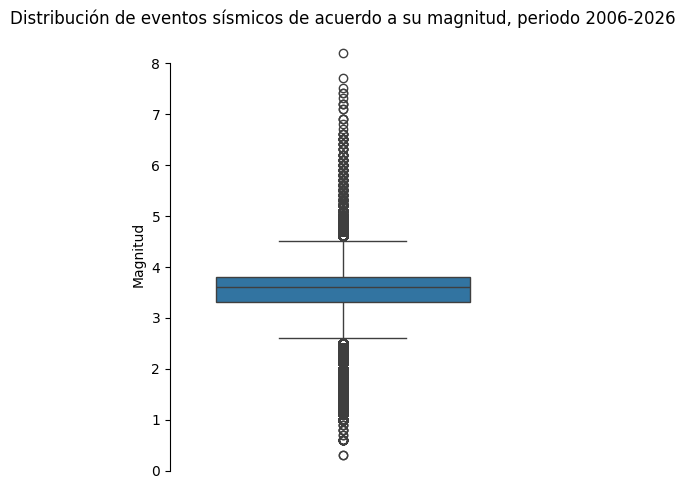


             count      mean       std  min  25%  50%  75%  max
Magnitud  360449.0  3.465265  0.549347  0.3  3.3  3.6  3.8  8.2


In [ ]:
# boxplot general (detección de outliers)

plt.figure(figsize=(4, 5))
sns.boxplot(y=data['Magnitud'])
sns.despine(offset=10, trim=True)
plt.title('Distribución de eventos sísmicos de acuerdo a su magnitud, periodo 2006-2026')
plt.tight_layout()
plt.show()

print()
print(data[['Magnitud']].describe().T)

- **Interpretación:** la mayoría de los sismos son de magnitud baja a moderada (alrededor de 3.3 a 3.8), con eventos débiles muy pequeños (no se siente, pero es registrado) y eventos fuertes poco frecuentes.

1. Muchos valores atípicos inferiores: puntos entre 0.3 y 2.5, formando una larga cola hacia abajo.
2. Valores atípicos superiores: puntos entre 4.6 y 8.2, que corresponden a los sismos fuertes. Son pocos en proporción, pero se extienden mucho.
3. Desviación estándar de 0.55: es baja frente al rango total (0.3 a 8.2), lo que confirma que la mayoría de los datos están concentrados y los extremos son poco frecuentes.
4. Dispersión asimétrica: hay más puntos atípicos hacia abajo que hacia arriba, pero los de arriba llegan más lejos del centro.


In [ ]:
# revisar dónde están el sismo de min y máx magnitud
data[data['Magnitud'].isin([0.3, 8.2])]

,Fecha,Hora,Magnitud,Latitud,Longitud,Profundidad,Referencia de localizacion,Fecha UTC,Hora UTC,Estatus
70549,2017-09-07,23:49:17,8.2,14.7610,-94.1030,45.9,"140 km al SUROESTE de PIJIJIAPAN, CHIS",2017-09-08,04:49:17,revisado
206418,2022-02-22,16:26:35,0.3,19.2805,-99.3332,7.0,"5 km al SUR de SAN LORENZO ACOPILCO, CDMX",2022-02-22,22:26:35,revisado
206419,2022-02-22,16:26:43,0.3,19.2860,-99.3388,7.0,"5 km al SUROESTE de SAN LORENZO ACOPILCO, CDMX",2022-02-22,22:26:43,revisado


De acuerdo al Servicio Geológico Mexicano- SGM, la escala Richter es la siguiente:
- Menos de 3.5: generalmente no se siente, pero es registrado.
- 3.5-5.4: a menudo se siente, pero sólo causa daños menores.
- 5.5-6.0: ocasiona daños ligeros a edificios.
- 6.1-6.9: puede ocasionar daños severos en áreas donde vive mucha gente.
- 7.0-7.9: terremoto mayor. Causa graves daños.
- 8 o mayor: gran terremoto. Destrucción total a comunidades cercanas.

Fuente: https://www.sgm.gob.mx/Web/MuseoVirtual/Informacion_complementaria/Escalas-sismos.html

Siendo los outliers validados y cumpliendo con los fines señalados, se mantendrán todos los registros.

In [ ]:
# revisar variables categóricas
cols_categoricas= ['Referencia de localizacion', 'Estatus']

for col in cols_categoricas:
    print(f'Únicos:\n{data[col].unique()}\n')
    print(f'Conteo de únicos:\n{data[col].nunique()}\n')
    print(f'Conteo total:\n{data[col].value_counts()}\n')
    print('-' * 30, '\n')

Únicos:
['18 km al ESTE de RIO GRANDE, OAX'
 '162 km al SURESTE de CD HIDALGO, CHIS'
 '46 km al ESTE de UNION HIDALGO, OAX' ...
 '2 km al NOROESTE de TECOMAN, COL' '159 km al OESTE de CIHUATLAN, JAL'
 '15 km al SURESTE de CARDENAS, SLP']

Conteo de únicos:
45628

Conteo total:
Referencia de localizacion
20 km al SUROESTE de PICHUCALCO, CHIS          2781
6 km al SUROESTE de SAN JOSE DEL CABO, BCS     2521
7 km al SUROESTE de SAN JOSE DEL CABO, BCS     2355
19 km al SUROESTE de PICHUCALCO, CHIS          1277
7 km al SUROESTE de SAN JOSE DEL CABO, BCS     1254
                                               ... 
58 km al SURESTE de S LUIS R COLORADO, SON        1
87 km al NORESTE de SAN FELIPE, BC                1
84 km al NORESTE de SAN FELIPE, BC                1
2 km al NORESTE de MORELOS, MICH                  1
1 km al SUROESTE de MIXQUIAHUALA, HGO             1
Name: count, Length: 45628, dtype: int64

------------------------------ 

Únicos:
['revisado' 'verificado']

Conteo de úni

- Para la columna estatus, se observa que la suma (360,449) corresponde al total de registros y como están verificados/revisados, se puede eliminar, no es necesario para cálculos posteriores. Sin embargo, para 'Referencia de localización', se generará una columna con los nombres de los estados para conocer las regiones con más actividad sísmica.

In [ ]:
# generar columna con estados
data['Localizacion'] = (data['Referencia de localizacion']
                        .str.extract(r',\s*([A-Za-z\.]+)\s*$')[0]
                        .str.strip()
                        .str.upper())

print(data[['Referencia de localizacion', 'Localizacion']].head())

                 Referencia de localizacion Localizacion
0          18 km al ESTE de RIO GRANDE, OAX          OAX
1     162 km al SURESTE de CD HIDALGO, CHIS         CHIS
2       46 km al ESTE de UNION HIDALGO, OAX          OAX
3  73 km al SUR de CD LAZARO CARDENAS, MICH         MICH
4      17 km al NOROESTE de RIO GRANDE, OAX          OAX


In [ ]:
# revisar eventos por estados y datos consistentes
display(data['Localizacion'].unique())
display(data['Localizacion'].value_counts().sort_values(ascending=False))


array(['OAX', 'CHIS', 'MICH', 'GRO', 'SON', 'BCS', 'JAL', 'HGO', 'MEX',
       'VER', 'PUE', 'SIN', 'CDMX', 'COL', 'SLP', 'NAY', 'DGO', 'NL',
       'TAB', 'QR', 'GTO', 'ZAC', 'MOR', 'CAMP', 'BC', 'TAMS', 'COAH',
       'TLAX', 'CHIH', 'AGS', 'YUC', 'QRO', 'N'], dtype=object)

,count
Localizacion,
OAX,124373
GRO,63893
CHIS,58845
MICH,24903
BC,22516
BCS,19843
JAL,14072
COL,11925
VER,7570


- Se lee un valor N= 3, revisemos su ubicación.

In [ ]:
# ver las filas donde localizacion == 'N'
display(data.loc[data['Localizacion'] == 'N'])

,Fecha,Hora,Magnitud,Latitud,Longitud,Profundidad,Referencia de localizacion,Fecha UTC,Hora UTC,Estatus,Localizacion
176089,2021-02-05,18:36:19,3.7,25.748,-100.285,5.0,"2 km al NORESTE de CD S NICOLAS DE LOS GARZA, N",2021-02-06,00:36:19,revisado,N
176099,2021-02-05,21:24:13,3.7,25.748,-100.285,5.0,"2 km al NORESTE de CD S NICOLAS DE LOS GARZA, N",2021-02-06,03:24:13,revisado,N
176156,2021-02-06,17:33:52,3.5,25.748,-100.285,5.0,"2 km al NORESTE de CD S NICOLAS DE LOS GARZA, N",2021-02-06,23:33:52,revisado,N


In [ ]:
# CD S NICOLAS DE LOS GARZA pertenece al estado de Nuevo León, reemplazar los registros.
data['Localizacion'] = data['Localizacion'].replace({'N':'NL'})

- Finalmente organizaremos las columnas a trabajar con la data limpia.


In [ ]:
# extraer año y mes
data['Año']= data['Fecha'].dt.year
data['Mes']= data['Fecha'].dt.month

In [ ]:
# ordenar columnas
data = data[['Fecha', 'Año', 'Mes', 'Localizacion', 'Magnitud', 'Latitud', 'Longitud']]

In [ ]:
# revisar cambios
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 360449 entries, 0 to 360451
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Fecha         360449 non-null  datetime64[ns]
 1   Año           360449 non-null  int32         
 2   Mes           360449 non-null  int32         
 3   Localizacion  360449 non-null  object        
 4   Magnitud      360449 non-null  float64       
 5   Latitud       360449 non-null  float64       
 6   Longitud      360449 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int32(2), object(1)
memory usage: 19.3+ MB


# 📈 Sección 3 - Análisis de datos
- Generar visualizaciones que permitan contestar las preguntas objetivo.

##🔹Actividad sísmica anual en los últimos 20 años

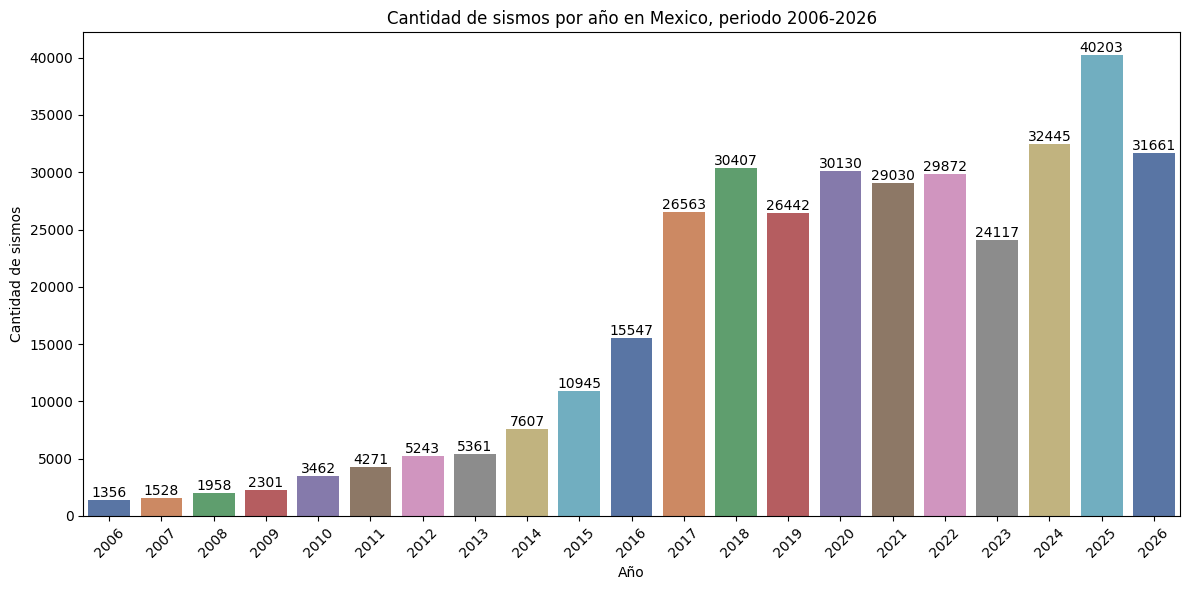

,year,count
19,2025,40203
18,2024,32445
20,2026,31661


In [ ]:
# contar eventos sísmicos por años y graficar
eventos_por_año = (data['Año'].value_counts().sort_index().reset_index())
eventos_por_año.columns = ['year', 'count']

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=eventos_por_año, x='year', y='count',
                 hue='year', palette="deep", legend=False)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Cantidad de sismos por año en Mexico, periodo 2006-2026')
plt.xlabel('Año')
plt.ylabel('Cantidad de sismos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# mostrar top 3
print()
display(eventos_por_año.sort_values('count', ascending=False).head(3))


- **Interpretación:** Es evidente que en los últimos 20 años destaca el 2025 con 40,203 eventos sísmicos a lo largo del año, seguido por 2024 con 32,445 y 2026 con 31,661 eventos.
- Recordar que se están tomando en cuenta los microsismos y que 2026 está  incompleto.

## **¿Está aumentando el número de sismos?**
- De acuerdo al Servicio Sismológico Nacional - SSN, el aumento de número de eventos sísmicos reportados (localizaciones) en los últimos años responde principalmente a la instalación de nuevas estaciones sismológicas y, con ello, una mejor cobertura de todo el territorio nacional para observar el fenómeno sísmico desde magnitudes más pequeñas, no necesariamente un incremento de la sismicidad. Por lo tanto, ahora tenemos la capacidad de detectar más.

- NOTA del SSN: Información sujeta a cambios. El número de sismos puede variar respecto a nuestros mapas de sismicidad anual.
El SSN revisa sismogramas históricos y recibe continuamente nuevos datos de sus estaciones sismológicas para mejorar la precisión en los parámetros reportados en caso necesario.

Fuentes:
http://www.ssn.unam.mx/divulgacion/preguntas/
http://www.ssn.unam.mx/sismicidad/estadisticas/

##🔹Magnitud de los sismos en el periodo 2006- 2026

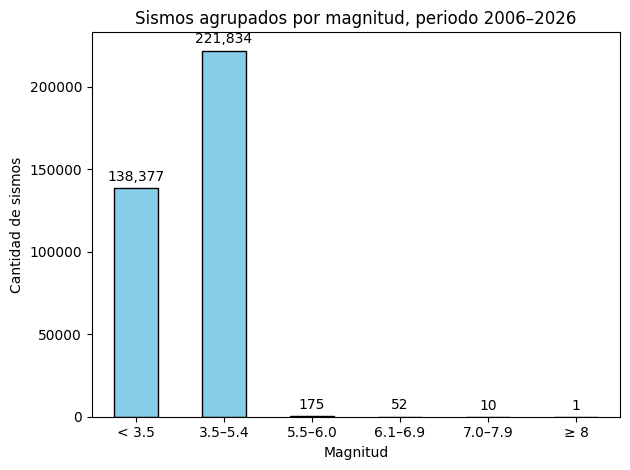

,count,mean,std,min,25%,50%,75%,max
Magnitud,360449.0,3.465265,0.549347,0.3,3.3,3.6,3.8,8.2


,Fecha,Hora,Magnitud,Latitud,Longitud,Profundidad,Referencia de localizacion,Fecha UTC,Hora UTC,Estatus
70549,2017-09-07,23:49:17,8.2,14.761,-94.103,45.9,"140 km al SUROESTE de PIJIJIAPAN, CHIS",2017-09-08,04:49:17,revisado


In [ ]:
# clasificar de acuerdo a la escala de magnitud mencionada anteriormente

bins = [0, 3.5, 5.5, 6.1, 7, 8, float('inf')]
clasificacion = ['< 3.5', '3.5–5.4', '5.5–6.0', '6.1–6.9', '7.0–7.9', '≥ 8']

eventos = pd.cut(data['Magnitud'], bins=bins, labels=clasificacion , right=False).value_counts(sort=False)

ax = eventos.plot(kind='bar', color='skyblue', edgecolor='black')

ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3)
plt.xlabel('Magnitud')
plt.ylabel('Cantidad de sismos')
plt.title('Sismos agrupados por magnitud, periodo 2006–2026')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print()
display(data[['Magnitud']].describe().T)

print()
display(data_original[data_original['Magnitud'].isin([8.2])])

- **Interpretación:** Los sismos en el rango de magnitud 3.5- 5.4 son los más frecuentes en los últimos 20 años en México, seguidos por los sismos de menor magnitud y microsismos.
- Por otro lado, los sismos de mayor magnitud (graves daños, destrucción total) son poco frecuentes. Se visualiza el sismo de magnitud 8.2 en PIJIJIAPAN, CHIS el 2017-09-07 a las	23:49:17 horas.

## **¿Cómo se mide la magnitud de un sismo?**
- Si bien empleamos la escala de Richter para clasificar los eventos sísmicos, en la actualidad para calcular la energía liberada en un sismo y determinar su magnitud se realizan cálculos matemáticos basados en los registros obtenidos por los sismómetros en diferentes estaciones.

- Entre otras, las magnitudes que se emplean son: (1) Magnitud de Coda Mc, (2) Magnitud de energía Me y (3) Magnitud de momento sísmico Mw.

Fuente:
http://www2.ssn.unam.mx:8080/recursos/imagenes/divulgacion/magnitudeintensidad.jpg

Al momento sabemos que el año con mayor registros de eventos sísmicos es 2025 y que las magnitudes más frecuentes en los últimos 20 años en México es de 3.5 a 5.4 (a menudo se siente, pero solo causa daños menores), ahora bien, **¿cómo se ha comportado la dinámica a lo largo de los 20 años que estamos analizando?**

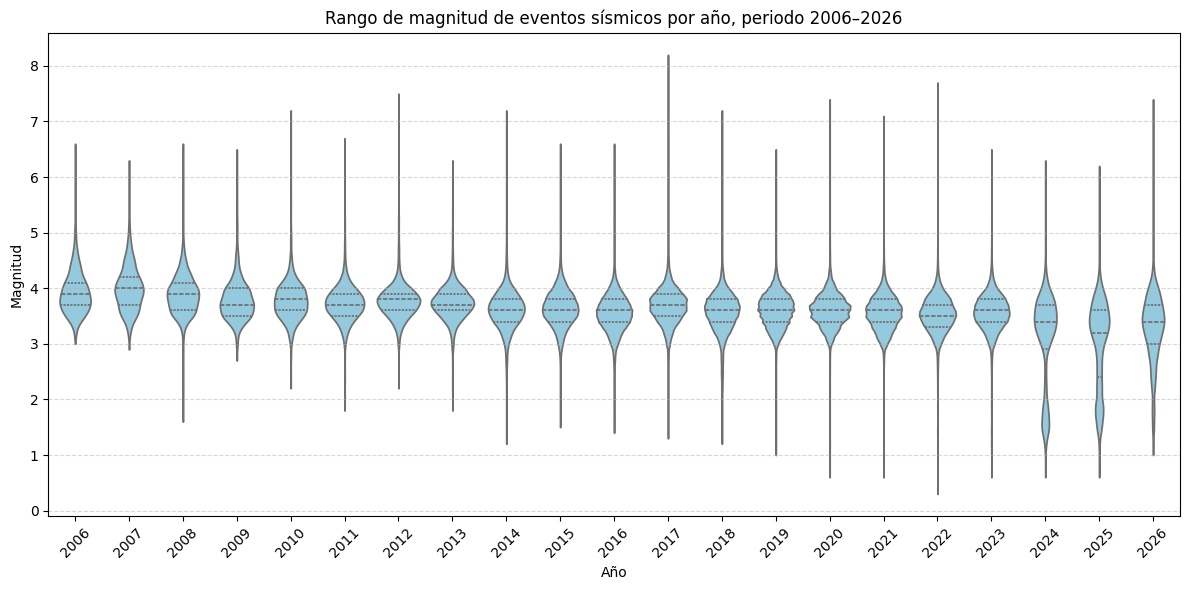

In [ ]:
plt.figure(figsize=(12, 6))

sns.violinplot(data=data, x='Año', y='Magnitud', color='skyblue', inner='quartile', cut=0)

plt.title('Rango de magnitud de eventos sísmicos por año, periodo 2006–2026')
plt.xlabel('Año')
plt.ylabel('Magnitud')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**- Interpretación:** los datos sugieren que la magnitud típica de los sismos no ha experimentado cambios drásticos a lo largo del periodo analizado, aunque existen eventos extremos.

- A partir de 2020 se tienen registros de sismos de magnitud < 1, hecho que se explica por el aumento de instalaciones de nuevas estaciones sismológicas y, con ello, una mejor cobertura para observar el fenómeno sísmico desde magnitudes más pequeñas, no necesariamente un incremento de la sismicidad.

- La mayor parte de los sismos se concentra en magnitudes moderadas, aproximadamente entre 3 y 4 (en la escala Richter, 3.5-5.4: a menudo se siente, pero sólo causa daños menores), durante la mayoría de los años.

- Las magnitudes típicas se mantienen relativamente estables durante el periodo 2006–2026, con valores centrales cercanos a 3.5–3.9.

- Todos los años presentan eventos de magnitud considerablemente superior a la magnitud típica, con máximos que superan 6 y un sismo de 8.2 (PIJIJIAPAN, CHIS el 2017-09-07 a las	23:49:17 horas) en los últimos 20 años.

- El año 2026 tiene registros hasta octubre.

##🔹¿En qué regiones tembló más en los últimos 20 años?

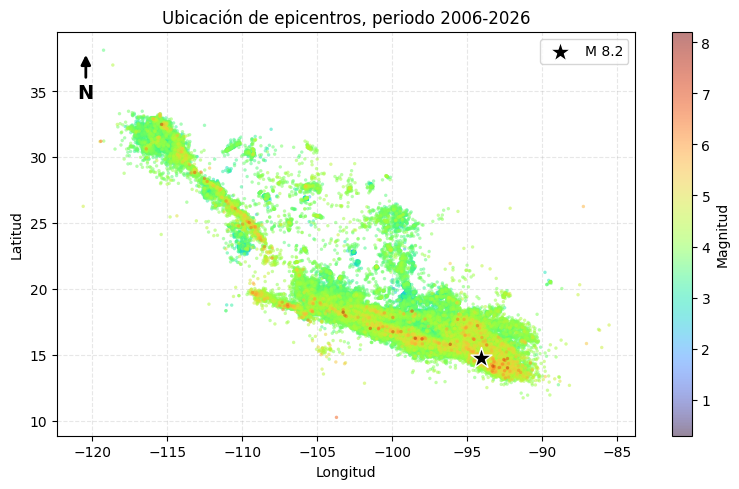

In [ ]:
# graficar epicentros para visualizar localización y ordenar por magnitud
data_ord = data.sort_values('Magnitud')

fig, ax = plt.subplots(figsize=(8, 5))

sc = ax.scatter(data_ord['Longitud'], data_ord['Latitud'],
                c=data_ord['Magnitud'], cmap='turbo',
                s=6, alpha=0.5, linewidths=0, zorder=2)
plt.colorbar(sc, label='Magnitud')

# destacar sismo = 8.2
sismo_max = data[data['Magnitud'] == data['Magnitud'].max()]
ax.scatter(sismo_max['Longitud'], sismo_max['Latitud'], marker='*', s=250, color='black', edgecolor='white', zorder=3, label=f"M {data['Magnitud'].max()}")

ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_title('Ubicación de epicentros, periodo 2006-2026')
ax.grid(True, linestyle='--', alpha=0.3, zorder=0)
ax.legend(loc='upper right')
plt.tight_layout()

# agregar el norte de referencia
ax.annotate('N', xy=(0.05, 0.95), xytext=(0.05, 0.85), xycoords='axes fraction', textcoords='axes fraction', ha='center', va='center', fontsize=14, fontweight='bold',arrowprops=dict(arrowstyle='-|>', color='black', lw=2))
plt.show()

**- Interpretación:** de acuerdo a la ubicación de los epicentros en sus coordenadas, se aprecia una mancha diagonal preferencial.

- Los sismos  de magnitud ≥ 6 son dispersos, pocos y aislados comparados con los de magnitud baja a moderada (3-4.5) que son predominantes.

- La estrella marca un evento puntual: el sismo de mayor intensidad en este lapso 2006-2026, de magnitud 8.2 en PIJIJIAPAN, CHIS el 2017-09-07 a las	23:49:17 horas.

Limitaciones: el gráfico no permite ver cuándo ocurrió cada evento, no se pueden identificar réplicas, enjambres ni cambios de actividad en el tiempo.

Veáse mapa de tectónica, pág. 10 en http://www.ssn.unam.mx/sismicidad/reportes-especiales/2017/SSNMX_rep_esp_20170907_Tehuantepec_M82.pdf

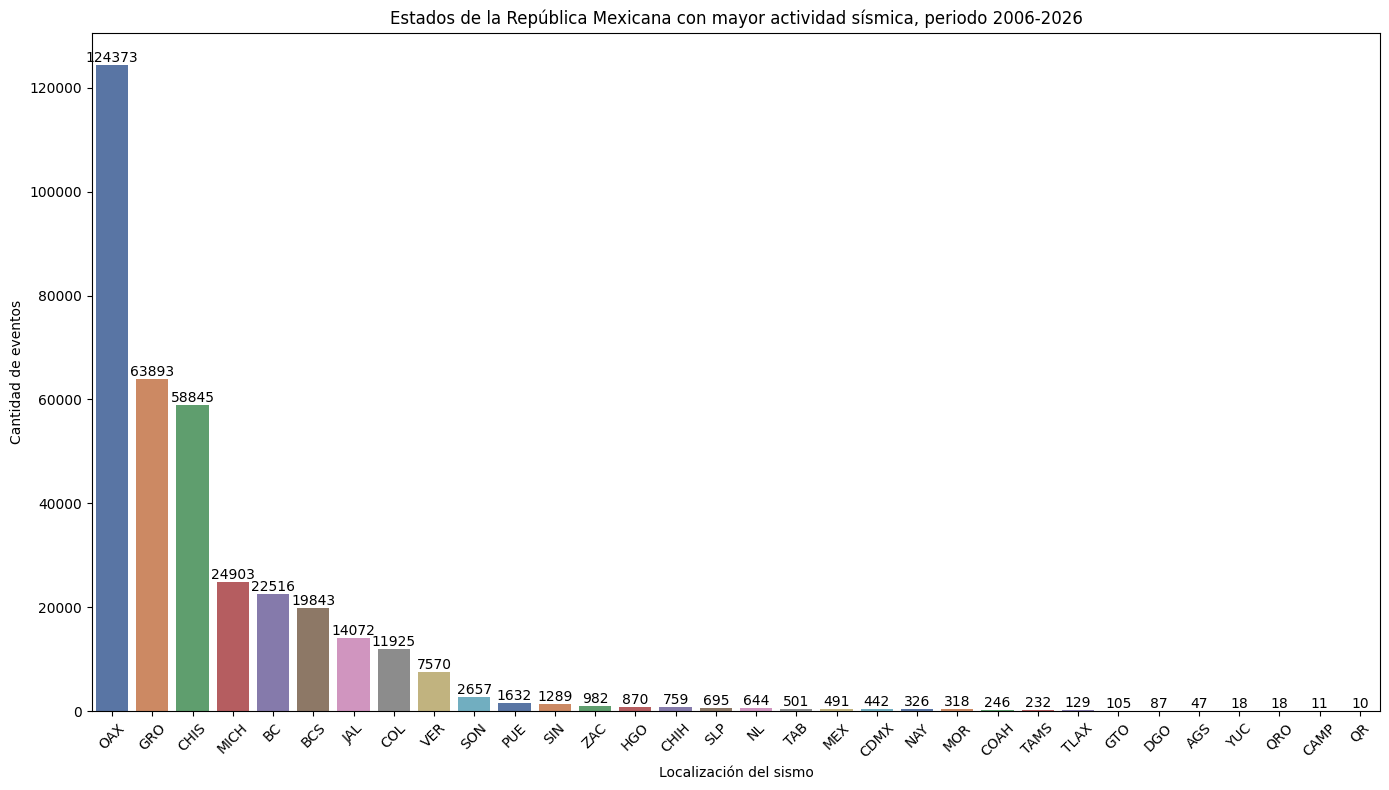

,lugar,count,porcentaje
0,OAX,124373,34.505020
1,GRO,63893,17.725947
2,CHIS,58845,16.325472
3,MICH,24903,6.908883
4,BC,22516,6.246653
5,BCS,19843,5.505078
6,JAL,14072,3.904020
7,COL,11925,3.308374
8,VER,7570,2.100158
9,SON,2657,0.737136


In [ ]:
# contar eventos sísmicos por ubicación
estado= (data['Localizacion'].value_counts().reset_index())
estado.columns = ['lugar', 'count']

plt.figure(figsize=(14, 8))
ax = sns.barplot(data=estado, x='lugar', y='count',
                 hue='lugar', palette="deep", legend=False)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Estados de la República Mexicana con mayor actividad sísmica, periodo 2006-2026')
plt.xlabel('Localización del sismo')
plt.ylabel('Cantidad de eventos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# mostrar top 10
print()

estado['porcentaje'] = estado['count'] / estado['count'].sum() * 100
top = estado.head(10).sort_values('porcentaje')
display(top.sort_values('porcentaje', ascending=False).head(10))

**- Interpretación:** los 3 estados que destacan notablemente por su alta actividad sísmica son Oaxaca con 124,373 sismos concentrando el 34.5 % de eventos en los últimos 20 años, seguido por el estado de Guerrero con 63,893 sismos y 17.7 % del total; finalmente Chiapas con 58,845 sismos y 16.32 %.

- Por otro lado, con menor actividad sísmica registrada en el intervalo evaluado, se encuentran los estados de Yucatán (18 sismos), Querétaro (18), Campeche (11)  y Quintana Roo (10).

- Los estados con mayor actividad sísmica se encuentran en la costa del Pacífico Mexicano, la cual es un área de subducción entre la placa de Cocos y la Norteamericana.

- Todos los estados de México tienen sismicidad. Sin embargo, las características tectónicas hacen que en algunos estados tiemble más que otros.
México es un país activo sísmicamente, su tectónica depende de  la interacción de cinco placas, por tal motivo, se presentan temblores todos los días, la mayoría de los cuales son de baja magnitud.

Fuente:
http://www2.ssn.unam.mx:8080/recursos/imagenes/divulgacion/regiones_vulnerables.jpg



##🔹¿Por qué tiembla mucho en la Ciudad de México?

In [ ]:
# conocer magnitudes min y max
cdmx = data.loc[data['Localizacion'] == 'CDMX', ['Localizacion', 'Fecha', 'Magnitud']]

tabla_cdmx = (cdmx.loc[[cdmx['Magnitud'].idxmax(), cdmx['Magnitud'].idxmin()]].reset_index(drop=True))
tabla_cdmx.insert(0, 'Tipo', ['Máxima', 'Mínima'])

display(tabla_cdmx)

,Tipo,Localizacion,Fecha,Magnitud
0,Máxima,CDMX,2025-11-19,3.9
1,Mínima,CDMX,2022-02-22,0.3


- **Interpretación:** En la Ciudad de México la actividad sísmica es poco numerosa (442 sismos en 2006-2026) y de baja magnitud (M<4), sin embargo, las condiciones del subsuelo de la cuenca de México hacen que los sismos que ocurren en la costa del país se sientan intensamente.


##🔹¿Es septiembre el mes de los sismos?

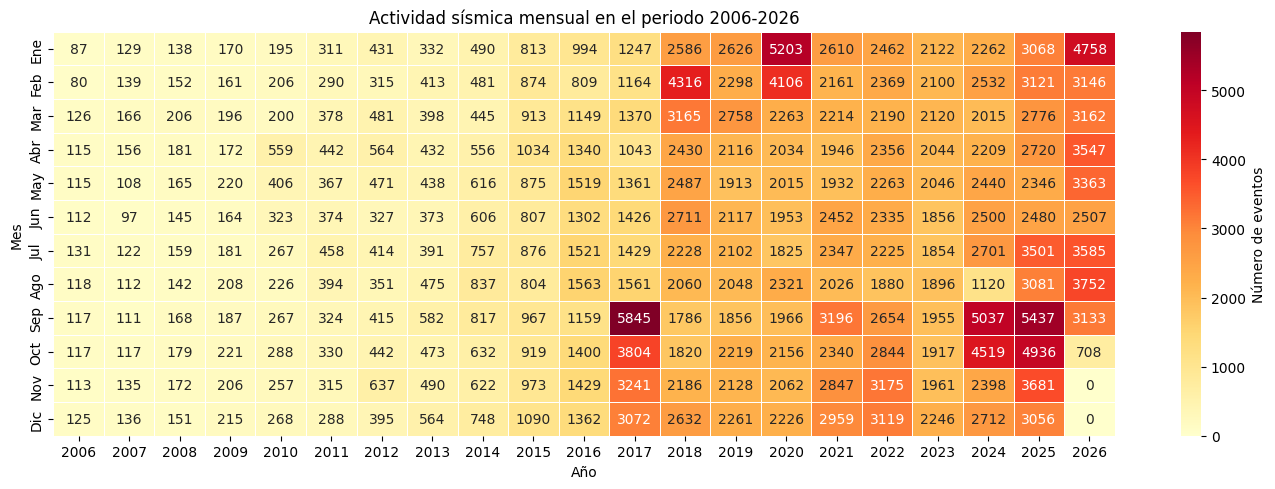

In [ ]:
# crear tabla de eventos mes/año
tabla = pd.crosstab(data['Mes'], data['Año'])

# nombrar meses
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
         'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
tabla.index = meses
tabla.columns.name = 'Año'

plt.figure(figsize=(14, 5))
sns.heatmap(tabla,
            annot=True,        # muestra el número en cada celda
            fmt='d',           # formato entero
            cmap='YlOrRd',
            linewidths=0.5,
            cbar_kws={'label': 'Número de eventos'})

plt.title('Actividad sísmica mensual en el periodo 2006-2026')
plt.xlabel('Año')
plt.ylabel('Mes')
plt.tight_layout()
plt.show()

- **Interpretación:** Los eventos sísmicos mensuales incluyen todas las magnitudes (incluyendo las que solo registra un sismómetro y son calificados como imperceptibles), no se halla un patrón estacional claro. Los meses de un mismo año tienen valores similares y los picos aparecen de forma irregular, entonces los sismos tectónicos no tienen relación con la época del año.

- Hay un salto marcado entre 2017 y 2018. Los conteos mensuales se duplican o más de un año al otro y se mantienen en ese nuevo nivel, lo que apunta a un cambio en la forma de detectar sismos.

- Septiembre de 2017 es el pico más fuerte (5,845 eventos). Coincide con la secuencia sísmica de Chiapas (M 8.2).

- Septiembre-octubre de 2024 y 2025 vuelven a mostrar picos (5,037 y 5,437 en septiembre; 4,519 y 4,936 en octubre). Superan el nivel habitual de esos años y sugieren secuencias de réplicas o enjambres importantes.

- Enero y febrero de 2018 y 2020 destacan (4,316 y 5,203 en 2018 y 2020 respectivamente). Pueden corresponder a secuencias de réplicas locales de eventos fuertes.


# 🚩 Limitantes
- Se ha mencionado que el aumento histórico refleja mejor monitoreo, no mayor actividad sísmica. La ampliación de la red de estaciones sísmicas, mejores algoritmos de detección y cambios en los criterios de publicación aumentan los eventos pequeños registrados. Esto impide comparar años antiguos con recientes de forma directa.
- Por lo anterior, se propone evaluar los sismos de mayor magnitud, revisar M>= 7.

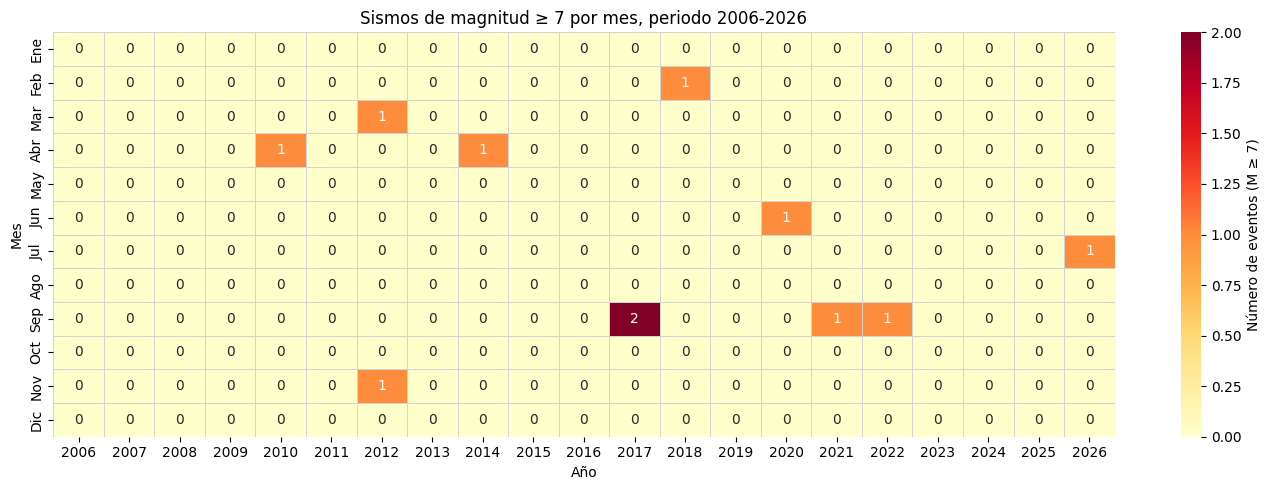

,Fecha,Año,Mes,Localizacion,Magnitud,Latitud,Longitud
19196,2012-11-07,2012,11,CHIS,7.3,14.0272,-92.3155
73671,2017-09-19,2017,9,PUE,7.1,18.3297,-98.6712
70549,2017-09-07,2017,9,CHIS,8.2,14.7610,-94.1030
221309,2022-09-19,2022,9,MICH,7.7,18.2377,-103.2690
191345,2021-09-07,2021,9,GRO,7.1,16.7553,-99.9533
350493,2026-07-17,2026,7,CHIS,7.4,14.1620,-93.2870
159912,2020-06-23,2020,6,OAX,7.4,15.8033,-96.1337
27097,2014-04-18,2014,4,GRO,7.2,17.0110,-101.4600
7775,2010-04-04,2010,4,BC,7.2,32.4700,-115.3700
15812,2012-03-20,2012,3,GRO,7.5,16.2640,-98.4570


In [ ]:
# buscar sismos por mes arriba de M= 7
data_m7 = data[data['Magnitud'] >= 7]

# crear tabla de eventos mes/año
tabla = pd.crosstab(data_m7['Mes'], data_m7['Año'])

# asegurar los 12 meses y todos los años del periodo (aunque tengan 0 eventos)
anios = range(int(data['Año'].min()), int(data['Año'].max()) + 1)
tabla = tabla.reindex(index=range(1, 13), columns=anios, fill_value=0)

# nombrar meses
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
         'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
tabla.index = meses
tabla.columns.name = 'Año'

plt.figure(figsize=(14, 5))
sns.heatmap(tabla,
            annot=True,        # muestra el número en cada celda
            fmt='d',           # formato entero
            cmap='YlOrRd',
            linewidths=0.5,
            linecolor='lightgray',
            cbar_kws={'label': 'Número de eventos (M ≥ 7)'})

plt.title('Sismos de magnitud ≥ 7 por mes, periodo 2006-2026')
plt.xlabel('Año')
plt.ylabel('Mes')
plt.tight_layout()
plt.show()

print()
display(data.loc[data['Magnitud'] >= 7].sort_values('Mes', ascending=False))

**- Interpretación:** Para los últimos 20 años, en septiembre se tienen registros de 4 sismos con M >= 7:
- 2017, PUE	7.1
- 2017,	CHIS	8.2
- 2022,	MICH	7.7
- 2021,	GRO	7.1

No hay patrón evidente ni muestra suficiente para relacionar los sismos con un mes en particular.

- Cabe señalar que el SSN tiene registros de grandes sismos:
- 8.4-8.7 en  1787 en las Costas de Oaxaca.
- 8.2 en 1932 en las costas de Colima y Jalisco.
- 8.1 en 1985 en las costas de Michoacán.
- 8.1 en 1995 en las costas de Colima.
- 8.2 en 2017 Golfo de Tehuantepec

Veáse http://www.ssn.unam.mx/sismicidad/reportes-especiales/

## ¿Es septiembre cuando más ha temblado? ##
No.
-  Desde que hay registros sísmicos en México, a partir del año 1900, ocurrieron 87 sismos considerados "grandes" por ser de magnitud mayor a 7,0, según las estadísticas del SSN.

Hay un empate en 12 sismos entre septiembre y diciembre en los últimos 121 años. Pero junio no está muy atrás, con 10 eventos sismicos de gran magnitud.

Eso muestra que en realidad esos tres meses acumulan la mayor actividad sísmica, pero por una diferencia marginal. El resto tienen registros variados.

Fuente: https://www.bbc.com/mundo/noticias-58576416

 ## ⚠ LOS SISMOS NO SE PUEDEN PREDECIR ##
 **- ¿Qué sí sabemos?**
 - Registros históricos con sismos de gran magnitud y detección mejorada en los últimos años.

 **- ¿Cuándo ocurrirá?**
 - No es posible saberlo.

  **- ¿Qué podemos hacer?**
  - Estar preparados y bien informados sobre qué hacer antes, durante y después.

   Fuente: http://www.ssn.unam.mx/recursos/imagenes/informacion/ssnmx_info_los_sismos_no_se_pueden_predecir.jpg
